# Forecasting Soil Moisture Indramayu (2014–2023) — LSTM Seq2Seq

**Skema evaluasi (tanpa kebocoran data):**

| Bagian | Periode | Kegunaan |
|---|---|---|
| Train | 2014 – 2021 | melatih model saat tuning |
| Validation | 52 minggu 2022 | memilih hyperparameter |
| Test | 52 minggu 2023 | evaluasi akhir, **dipakai sekali saja** |

- Scaler di-*fit* hanya pada data latih (tidak melihat val/test).
- Window latih hanya yang target-nya selesai sebelum periode val/test dimulai.
- Setiap kombinasi hyperparameter dilatih dengan beberapa seed, lalu skornya dirata-rata.
- Model final dilatih ulang pada Train + Val, lalu dievaluasi sekali pada Test.

## 0. Setup & seed

In [1]:
import os
os.environ["PYTHONHASHSEED"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import itertools
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error, r2_score)

warnings.filterwarnings("ignore")
tf.config.experimental.enable_op_determinism()

def set_seed(seed: int) -> None:
    """Kunci semua sumber randomness (Python, NumPy, TensorFlow)."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Konfigurasi

In [2]:
# ---- Path Kaggle ----
# Upload file .xlsx sebagai Kaggle Dataset, lalu sesuaikan path di bawah.
# Kalau file tidak ditemukan, notebook mengunduh dari GitHub (Internet di Settings harus ON).
KAGGLE_INPUT = "/kaggle/input"
FILE_NAME    = "SM_Avg_Weekly_Indramayu_2014_2023.xlsx"
FALLBACK_URL = ("https://raw.githubusercontent.com/rafiadabhi/soil-moisture-lstm-indramayu/main/"
                "data/SM_Avg_Weekly_Indramayu_2014_2023.xlsx")
OUTPUT_DIR   = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# ---- Window ----
LOOK_BACK        = 52   # input: 52 minggu terakhir
FORECAST_HORIZON = 52   # output: 52 minggu ke depan

# ---- Model ----
UNITS = 64

# ---- Grid search ----
PARAM_GRID = {
    "batch_size": [16, 32, 64],
    "epochs":     [50, 100],
    "dropout":    [0.05, 0.1],
}
SEEDS = [0, 1, 2]   # tiap kombinasi dilatih dengan beberapa seed lalu dirata-rata

## 2. Load data

In [3]:
def find_data_file(root: str, name: str):
    if not os.path.isdir(root):
        return None
    for dirpath, _, files in os.walk(root):
        if name in files:
            return os.path.join(dirpath, name)
    return None

path = find_data_file(KAGGLE_INPUT, FILE_NAME)
source = path if path else FALLBACK_URL
print("Sumber data:", source)

data = pd.read_excel(source)
data["time"] = pd.to_datetime(data["time"])
data = data.sort_values("time").reset_index(drop=True)

assert data["sm"].isna().sum() == 0, "Ada missing value pada kolom sm"
assert data["time"].diff().dropna().dt.days.eq(7).all(), "Data tidak mingguan berurutan"

series = data["sm"].to_numpy(dtype="float32").reshape(-1, 1)
dates  = data["time"].to_numpy()
N = len(series)
print(f"Jumlah observasi: {N} ({data['time'].min().date()} s.d. {data['time'].max().date()})")

Sumber data: https://raw.githubusercontent.com/rafiadabhi/soil-moisture-lstm-indramayu/main/data/SM_Avg_Weekly_Indramayu_2014_2023.xlsx
Jumlah observasi: 522 (2014-01-05 s.d. 2023-12-31)


## 3. Fungsi bantu: windowing, split, model, metrik

In [4]:
def make_windows(arr, look_back, horizon):
    """Bentuk pasangan (X, y) seq2seq dari array 2D (n, 1)."""
    X, y = [], []
    for i in range(len(arr) - look_back - horizon + 1):
        X.append(arr[i:i + look_back])
        y.append(arr[i + look_back:i + look_back + horizon])
    return np.asarray(X, dtype="float32"), np.asarray(y, dtype="float32")


def prepare_split(raw, look_back, horizon):
    """
    Bagian terakhir sepanjang `horizon` dijadikan target evaluasi.
    - Scaler di-fit hanya pada raw[:-horizon] (data latih).
    - Window latih dibentuk hanya dari raw[:-horizon], sehingga tidak ada
      target latih yang overlap dengan periode evaluasi.
    - Input evaluasi = `look_back` minggu tepat sebelum periode evaluasi.
    """
    train_raw = raw[:-horizon]
    scaler = StandardScaler().fit(train_raw)

    train_scaled = scaler.transform(train_raw)
    X_tr, y_tr = make_windows(train_scaled, look_back, horizon)

    X_ev = scaler.transform(raw[-horizon - look_back:-horizon])[np.newaxis, ...]
    y_ev = raw[-horizon:].flatten()          # skala asli
    return X_tr, y_tr, X_ev.astype("float32"), y_ev, scaler


def build_model(look_back, horizon, units, dropout):
    model = keras.Sequential([
        layers.Input(shape=(look_back, 1)),
        layers.LSTM(units, activation="relu"),                         # encoder
        layers.RepeatVector(horizon),                                  # jembatan
        layers.LSTM(units, activation="relu", return_sequences=True),  # decoder
        layers.Dropout(dropout),
        layers.TimeDistributed(layers.Dense(1)),
    ])
    model.compile(optimizer="adam", loss="mae")
    return model


def fit_predict(X_tr, y_tr, X_ev, scaler, batch_size, epochs, dropout, seed, verbose=0):
    keras.backend.clear_session()
    set_seed(seed)
    model = build_model(LOOK_BACK, FORECAST_HORIZON, UNITS, dropout)
    hist = model.fit(X_tr, y_tr, epochs=epochs, batch_size=batch_size,
                     shuffle=True, verbose=verbose)
    pred_scaled = model.predict(X_ev, verbose=0)[0]
    pred = scaler.inverse_transform(pred_scaled).flatten()
    return model, hist, pred


def metrics(y_true, y_pred):
    return {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2":   r2_score(y_true, y_pred),
    }

## 4. Split

- **Tuning**: seri tanpa 2023 → periode evaluasi = 2022 (validation).
- **Final**: seri lengkap → periode evaluasi = 2023 (test).

In [5]:
tune_raw = series[:-FORECAST_HORIZON]   # 2014–2022 (test 2023 disisihkan)
X_tr, y_tr, X_val, y_val, scaler_tune = prepare_split(tune_raw, LOOK_BACK, FORECAST_HORIZON)

val_dates  = dates[N - 2 * FORECAST_HORIZON:N - FORECAST_HORIZON]
test_dates = dates[N - FORECAST_HORIZON:]

print("X_train :", X_tr.shape, "| y_train:", y_tr.shape)
print("Val     :", pd.Timestamp(val_dates[0]).date(),  "s.d.", pd.Timestamp(val_dates[-1]).date())
print("Test    :", pd.Timestamp(test_dates[0]).date(), "s.d.", pd.Timestamp(test_dates[-1]).date())

X_train : (315, 52, 1) | y_train: (315, 52, 1)
Val     : 2022-01-09 s.d. 2023-01-01
Test    : 2023-01-08 s.d. 2023-12-31


## 5. Grid search pada validation set (2022)

In [6]:
results = []
combos = list(itertools.product(*PARAM_GRID.values()))
for k, (bs, ep, dr) in enumerate(combos, 1):
    scores = []
    for s in SEEDS:
        _, hist, pred = fit_predict(X_tr, y_tr, X_val, scaler_tune, bs, ep, dr, seed=s)
        m = metrics(y_val, pred)
        m["train_loss"] = hist.history["loss"][-1]
        scores.append(m)
    sc = pd.DataFrame(scores)
    row = {"batch_size": bs, "epochs": ep, "dropout": dr}
    for col in ["MAE", "RMSE", "MAPE", "R2", "train_loss"]:
        row[f"val_{col}_mean" if col != "train_loss" else "train_loss_mean"] = sc[col].mean()
    row["val_MAE_std"] = sc["MAE"].std()
    results.append(row)
    print(f"[{k:2d}/{len(combos)}] bs={bs:<3} ep={ep:<4} drop={dr:<5} "
          f"-> val MAE {row['val_MAE_mean']:.4f} ± {row['val_MAE_std']:.4f}")

res_df = pd.DataFrame(results).sort_values("val_MAE_mean").reset_index(drop=True)
res_df.to_csv(os.path.join(OUTPUT_DIR, "grid_search_results.csv"), index=False)
res_df

E0000 00:00:1795030534.152107      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795030646.528718      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

[ 1/12] bs=16  ep=50   drop=0.05  -> val MAE 0.0358 ± 0.0035


E0000 00:00:1795030979.374451      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1795031090.027426      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

E0000 00:00:1795031200.325720      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


[ 2/12] bs=16  ep=50   drop=0.1   -> val MAE 0.0364 ± 0.0076


E0000 00:00:1795031415.284972      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1795031628.519671      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

... (16 outputs left out)

[11/12] bs=64  ep=100  drop=0.05  -> val MAE 0.0361 ± 0.0029


E0000 00:00:1795033957.535346      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1795034019.360769      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

[12/12] bs=64  ep=100  drop=0.1   -> val MAE 0.0362 ± 0.0024


,batch_size,epochs,dropout,val_MAE_mean,val_RMSE_mean,val_MAPE_mean,val_R2_mean,train_loss_mean,val_MAE_std
0,32,100,0.05,0.028602,0.035767,8.808633,0.067672,0.230234,0.004589
1,32,100,0.10,0.031518,0.039056,9.694203,-0.110904,0.233327,0.005613
2,64,50,0.10,0.035652,0.041823,10.764144,-0.254689,0.372266,0.002895
3,16,50,0.05,0.035823,0.042700,10.951521,-0.318236,0.293956,0.003514
4,64,100,0.05,0.036063,0.043850,11.081406,-0.380133,0.279651,0.002911
5,64,100,0.10,0.036212,0.043522,11.075159,-0.360061,0.268880,0.002369
6,16,50,0.10,0.036433,0.045138,11.255792,-0.499982,0.292347,0.007587
7,16,100,0.10,0.036449,0.046538,11.296870,-0.568081,0.223598,0.004891
8,32,50,0.10,0.036684,0.043680,11.138603,-0.372318,0.304881,0.003506
9,32,50,0.05,0.037399,0.044170,11.432188,-0.411320,0.302709,0.004449


In [7]:
best = res_df.iloc[0]
BEST_BATCH = int(best["batch_size"])
BEST_EPOCH = int(best["epochs"])
BEST_DROP  = float(best["dropout"])
print(f"Konfigurasi terbaik (berdasarkan val MAE): batch={BEST_BATCH}, epochs={BEST_EPOCH}, dropout={BEST_DROP}")

Konfigurasi terbaik (berdasarkan val MAE): batch=32, epochs=100, dropout=0.05


## 6. Model final: latih ulang pada Train + Val, evaluasi sekali pada Test (2023)

In [8]:
X_full, y_full, X_test, y_test, scaler_full = prepare_split(series, LOOK_BACK, FORECAST_HORIZON)
print("X_train_final:", X_full.shape)

test_preds, test_scores = [], []
for s in SEEDS:
    model, hist, pred = fit_predict(X_full, y_full, X_test, scaler_full,
                                    BEST_BATCH, BEST_EPOCH, BEST_DROP, seed=s)
    test_preds.append(pred)
    test_scores.append(metrics(y_test, pred))

test_scores = pd.DataFrame(test_scores, index=[f"seed {s}" for s in SEEDS])
pred_ens = np.mean(test_preds, axis=0)     # rata-rata prediksi antar seed

summary = pd.concat([
    test_scores,
    test_scores.agg(["mean", "std"]).rename(index={"mean": "mean (per seed)", "std": "std (per seed)"}),
    pd.DataFrame([metrics(y_test, pred_ens)], index=["ensemble (rata-rata prediksi)"]),
])
summary.to_csv(os.path.join(OUTPUT_DIR, "test_metrics.csv"))
print("=== TEST METRICS (2023) ===")
summary.round(4)

X_train_final: (367, 52, 1)


E0000 00:00:1795034213.423119      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1795034346.668568      23 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

=== TEST METRICS (2023) ===


,MAE,RMSE,MAPE,R2
seed 0,0.0228,0.0305,7.9650,0.6337
seed 1,0.0234,0.0334,7.6617,0.5610
seed 2,0.0244,0.0346,7.9810,0.5286
mean (per seed),0.0235,0.0329,7.8692,0.5744
std (per seed),0.0008,0.0021,0.1799,0.0538
ensemble (rata-rata prediksi),0.0213,0.0306,7.0846,0.6324


In [9]:
forecast_df = pd.DataFrame({"time": test_dates, "actual": y_test, "lstm_forecast": pred_ens})
forecast_df.to_csv(os.path.join(OUTPUT_DIR, "lstm_forecast_2023.csv"), index=False)
model.save(os.path.join(OUTPUT_DIR, "lstm_seq2seq_final.keras"))   # model seed terakhir
forecast_df.head()

,time,actual,lstm_forecast
0,2023-01-08,0.381651,0.354609
1,2023-01-15,0.371488,0.370888
2,2023-01-22,0.380467,0.373876
3,2023-01-29,0.379076,0.371608
4,2023-02-05,0.375319,0.368525


## 7. Visualisasi

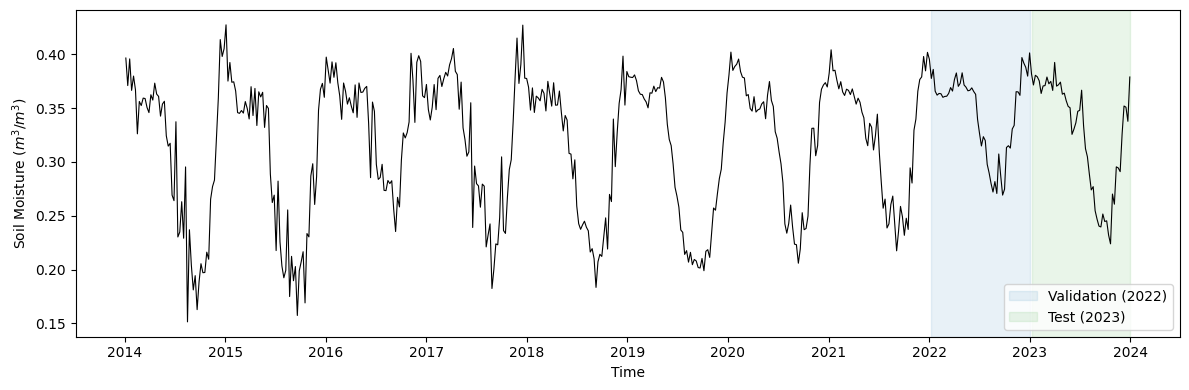

In [10]:
plt.figure(figsize=(12, 4))
plt.plot(data["time"], data["sm"], color="black", linewidth=0.8)
plt.axvspan(val_dates[0],  val_dates[-1],  color="tab:blue",  alpha=0.1, label="Validation (2022)")
plt.axvspan(test_dates[0], test_dates[-1], color="tab:green", alpha=0.1, label="Test (2023)")
plt.xlabel("Time"); plt.ylabel("Soil Moisture ($m^3/m^3$)")
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "series_split.png"), dpi=300)
plt.show()

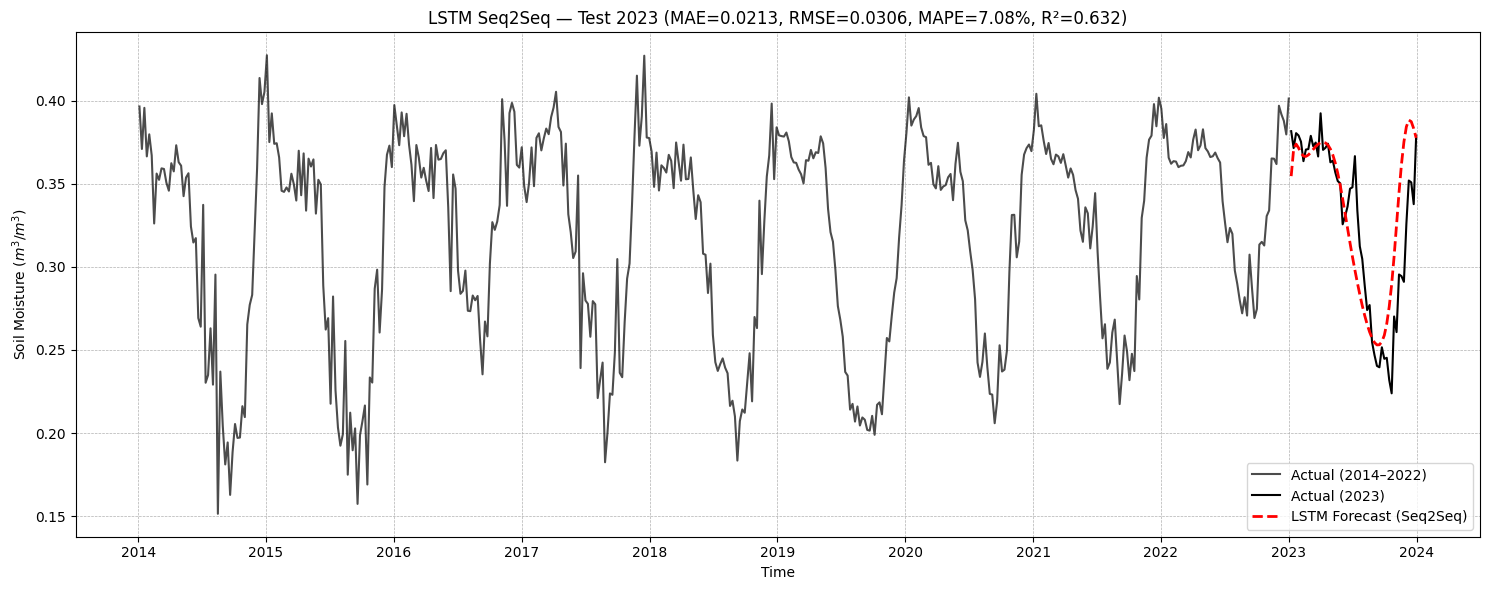

In [11]:
m_ens = metrics(y_test, pred_ens)

plt.figure(figsize=(15, 6))
plt.plot(dates[:-FORECAST_HORIZON], series[:-FORECAST_HORIZON, 0],
         color="black", alpha=0.7, label="Actual (2014–2022)")
plt.plot(test_dates, y_test, color="black", linewidth=1.5, label="Actual (2023)")
plt.plot(test_dates, pred_ens, color="red", linestyle="--", linewidth=2, label="LSTM Forecast (Seq2Seq)")
plt.title(f"LSTM Seq2Seq — Test 2023 (MAE={m_ens['MAE']:.4f}, RMSE={m_ens['RMSE']:.4f}, "
          f"MAPE={m_ens['MAPE']:.2f}%, R²={m_ens['R2']:.3f})")
plt.xlabel("Time"); plt.ylabel("Soil Moisture ($m^3/m^3$)")
plt.grid(True, linestyle="--", linewidth=0.5)
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "forecast_full.png"), dpi=300)
plt.show()

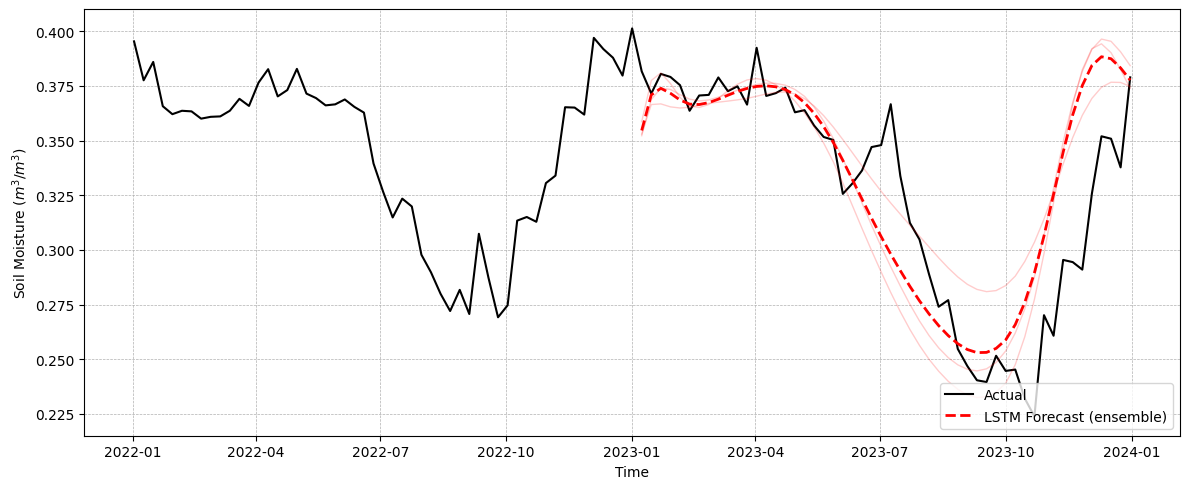

In [12]:
# Zoom: 2022–2023
plt.figure(figsize=(12, 5))
mask = data["time"] >= "2022-01-01"
plt.plot(data.loc[mask, "time"], data.loc[mask, "sm"], color="black", label="Actual")
for p in test_preds:
    plt.plot(test_dates, p, color="red", alpha=0.2, linewidth=1)
plt.plot(test_dates, pred_ens, color="red", linestyle="--", linewidth=2, label="LSTM Forecast (ensemble)")
plt.xlabel("Time"); plt.ylabel("Soil Moisture ($m^3/m^3$)")
plt.grid(True, linestyle="--", linewidth=0.5)
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "forecast_zoom.png"), dpi=300)
plt.show()